# 01b - TF Flowers + lớp "Khác" (mô hình 6 lớp, v1-khac)

Người phụ trách: Hân

Tuần 11–12 (kiểm thử mức L3): thêm lớp Khác vào **v1**, chỉ dùng TF Flowers. Ảnh tự thu thập ghép sau ở notebook 02 (tuần 13–14).

Lớp `other` ("Khác") gồm 2 phần, lấy từ các bộ dữ liệu công khai (tải bản sao trên Hugging Face, vì máy chủ gốc
của Oxford không truy cập được và máy chủ Caltech chặn tải bằng Python):
- **Hoa ngoài 5 loài**: Oxford 102 Flowers (bỏ các loài trùng hoặc rất giống 5 loài của Anthea).
- **Không phải hoa**: Caltech-101 (người, động vật, xe cộ, đồ vật…) và Imagenette (nhà thờ, xe rác, cây xăng…).

5 lớp hoa dùng nguyên bản chia TF Flowers của notebook 01 (`tf_flowers_split.zip`), chỉ thêm thư mục `other/`.
Kết quả lưu vào `models_khac/` trên Drive, **không ghi đè** `models/`.

Cell 1 – Thư viện, kiểm tra GPU, cố định seed

In [26]:
import os, io, json, shutil, random, datetime
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'KHÔNG CÓ – chọn Runtime → Change runtime type → T4 GPU')

SEED = 123
keras.utils.set_random_seed(SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Cell 2 – Kết nối Google Drive, khai báo đường dẫn

In [27]:
from google.colab import drive
drive.mount('/content/drive')

ROOT         = '/content/drive/MyDrive/flower-classifier'
MODEL_DIR    = f'{ROOT}/models_khac'                   # KHÔNG ghi đè models/
CKPT_PATH    = f'{ROOT}/checkpoints/best_khac.keras'
SPLIT_ZIP    = f'{ROOT}/data/tf_flowers_split.zip'     # notebook 01: TF Flowers chia 70/15/15
SPLIT_DIR    = '/content/tf_flowers_split'
OTHER_ZIP    = f'{ROOT}/data/other_split.zip'          # Cell 4 tạo lần đầu; lần sau giải nén lại cho giống hệt

for d in [MODEL_DIR, f'{ROOT}/checkpoints', f'{ROOT}/data']:
    os.makedirs(d, exist_ok=True)

FLOWERS     = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
CLASS_NAMES = FLOWERS + ['other']    # "other" ở CUỐI: 5 loài giữ đúng số thứ tự 0–4 như v1
VERSION     = 'v1-khac'
THRESHOLD   = 0.5                    # ngưỡng "chưa chắc chắn", giống v1
IMG_SIZE    = (180, 180)
BATCH_SIZE  = 32

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cell 3 – Giải nén TF Flowers (bản chia cố định của notebook 01)

In [28]:
shutil.rmtree(SPLIT_DIR, ignore_errors=True)        # giải nén lại từ đầu: xóa luôn thư mục other/ của lần chạy trước
shutil.unpack_archive(SPLIT_ZIP, SPLIT_DIR)          # -> /content/tf_flowers_split/{train,val,test}/<loài>

def count(folder):
    return {c: len(os.listdir(f'{folder}/{c}')) for c in sorted(os.listdir(folder))}

for split in ['train', 'val', 'test']:
    print(f'{split:5}', count(f'{SPLIT_DIR}/{split}'))

train {'daisy': 445, 'dandelion': 630, 'roses': 449, 'sunflowers': 491, 'tulips': 561}
val   {'daisy': 94, 'dandelion': 134, 'roses': 96, 'sunflowers': 104, 'tulips': 119}
test  {'daisy': 94, 'dandelion': 134, 'roses': 96, 'sunflowers': 104, 'tulips': 119}


Cell 4 – Tạo lớp Khác: hoa ngoài 5 loài + ảnh không phải hoa, chia cố định 70/15/15

In [29]:
# Hoa trùng hoặc rất giống 5 loài của Anthea: bỏ, để lớp Khác không chứa ảnh mà người xem cũng gọi là cúc, hồng…
OXFORD_SKIP  = ['oxeye daisy', 'barbeton daisy', 'common dandelion', "colt's foot",
                'rose', 'sunflower', 'black-eyed susan']
# Caltech-101: bỏ 3 nhóm là hoa, và background_google (ảnh ngẫu nhiên, có thể lẫn hoa)
CALTECH_SKIP = ['lotus', 'sunflower', 'water_lilly', 'background_google']
OTHER_DIR = '/content/other_split'

HF_API  = 'https://huggingface.co/api/datasets'
HF_INFO = 'https://datasets-server.huggingface.co/info?dataset='

def load_by_class(dataset, skip):
    """Tải một bộ ảnh trên Hugging Face (dạng file parquet) -> {tên lớp con: [ảnh dạng bytes]}."""
    info = requests.get(HF_INFO + dataset).json()
    names = info['dataset_info']['default']['features']['label']['names']   # tên lớp, theo số nhãn 0, 1, 2…
    files = requests.get(f'{HF_API}/{dataset}/parquet/default').json()      # {'train': [link, ...], 'test': [...]}
    by_class = {}
    for links in files.values():                        # gộp mọi tập con: train, validation, test
        for link in links:
            response = requests.get(link)
            response.raise_for_status()
            table = pd.read_parquet(io.BytesIO(response.content))          # mỗi dòng: ảnh (bytes) + nhãn (số)
            for image, label in zip(table['image'], table['label']):
                cls = names[label].strip()
                if cls not in skip:
                    by_class.setdefault(cls, []).append(image['bytes'])
    return by_class

def sample_evenly(by_class, n, rng):
    """Lấy n ảnh, chia đều cho các lớp con (mỗi lớp con vài tấm) để lớp Khác đa dạng nhất."""
    per_class = -(-n // len(by_class))            # chia làm tròn lên
    picked = []
    for cls in sorted(by_class):
        picked += rng.sample(by_class[cls], min(per_class, len(by_class[cls])))
    rng.shuffle(picked)
    return picked[:n]

if os.path.exists(OTHER_ZIP):
    shutil.rmtree(OTHER_DIR, ignore_errors=True)
    shutil.unpack_archive(OTHER_ZIP, OTHER_DIR)
else:
    shutil.rmtree(OTHER_DIR, ignore_errors=True)   # bắt đầu từ thư mục trống, không lẫn ảnh của lần chạy trước
    # Lớp Khác cỡ trung bình 5 lớp hoa: số ảnh train trung bình / 0.70 = tổng cả 3 tập
    total = round(np.mean([len(os.listdir(f'{SPLIT_DIR}/train/{c}')) for c in FLOWERS]) / 0.70)
    half = total // 2

    print('Đang tải 3 bộ ảnh (khoảng 800 MB, vài phút)…')
    oxford     = load_by_class('dpdl-benchmark/oxford_flowers102', OXFORD_SKIP)   # Oxford 102 Flowers
    caltech    = load_by_class('flwrlabs/caltech101', CALTECH_SKIP)              # Caltech-101
    imagenette = load_by_class('johnowhitaker/imagenette2-320', [])              # Imagenette 320px
    not_flower = {**caltech, **imagenette}
    print(f'Hoa ngoài 5 loài: {len(oxford)} loài | Không phải hoa: {len(not_flower)} nhóm | Lớp Khác: {total} ảnh')

    rng = random.Random(42)   # bản chia cố định, không đổi theo SEED (giống notebook 01)
    # Tên file ghi rõ nửa nào ("hoakhac" / "khonghoa") để Cell 9 đo riêng từng nửa
    images = ([('hoakhac', data) for data in sample_evenly(oxford, half, rng)] +
              [('khonghoa', data) for data in sample_evenly(not_flower, total - half, rng)])
    rng.shuffle(images)
    n = int(len(images) * 0.15)
    parts = {'test': images[:n], 'val': images[n:2 * n], 'train': images[2 * n:]}
    for split, items in parts.items():
        os.makedirs(f'{OTHER_DIR}/{split}/other', exist_ok=True)
        for i, (kind, data) in enumerate(items):
            # Lưu lại thành JPEG màu RGB: Caltech có ảnh xám, Imagenette có vài ảnh CMYK mà TensorFlow không đọc được
            Image.open(io.BytesIO(data)).convert('RGB').save(f'{OTHER_DIR}/{split}/other/{kind}_{split}_{i:04d}.jpg', quality=95)
    shutil.make_archive(OTHER_ZIP[:-4], 'zip', OTHER_DIR)

# Ghép vào TF Flowers -> train, val, test đều có 6 thư mục con. 5 loài trong test vẫn là đúng tập đã chấm v1
for split in ['train', 'val', 'test']:
    shutil.copytree(f'{OTHER_DIR}/{split}/other', f'{SPLIT_DIR}/{split}/other', dirs_exist_ok=True)

counts = {split: count(f'{SPLIT_DIR}/{split}') for split in ['train', 'val', 'test']}
print(json.dumps(counts, indent=2))

{
  "train": {
    "daisy": 445,
    "dandelion": 630,
    "other": 516,
    "roses": 449,
    "sunflowers": 491,
    "tulips": 561
  },
  "val": {
    "daisy": 94,
    "dandelion": 134,
    "other": 110,
    "roses": 96,
    "sunflowers": 104,
    "tulips": 119
  },
  "test": {
    "daisy": 94,
    "dandelion": 134,
    "other": 110,
    "roses": 96,
    "sunflowers": 104,
    "tulips": 119
  }
}


Cell 5 – Tạo tf.data, lưu class_names.json

In [30]:
def load_dir(folder, class_names, shuffle):
    # class_names: đặt thứ tự lớp bằng tay. Để Keras tự xếp theo ABC thì "other" sẽ nằm giữa dandelion và roses
    return keras.utils.image_dataset_from_directory(
        folder, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_names=class_names, shuffle=shuffle, seed=SEED)

train_ds   = load_dir(f'{SPLIT_DIR}/train', CLASS_NAMES, shuffle=True)
val_ds     = load_dir(f'{SPLIT_DIR}/val',   CLASS_NAMES, shuffle=False)
test_ds    = load_dir(f'{SPLIT_DIR}/test',  CLASS_NAMES, shuffle=False)
test_files = test_ds.file_paths                                 # Cell 9 dùng để tách 2 nửa của lớp Khác
class_names = train_ds.class_names
print(class_names)

with open(f'{MODEL_DIR}/class_names.json', 'w') as f:
    json.dump(class_names, f)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 3092 files belonging to 6 classes.
Found 657 files belonging to 6 classes.
Found 657 files belonging to 6 classes.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips', 'other']


Cell 6 – Xây mô hình CNN (giống hệt v1, chỉ khác lớp cuối là Softmax 6)

In [31]:
L2 = regularizers.l2(1e-4)   # phạt trọng số lớn (mục 3 – Regularization)

model = keras.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomHue(0.1, value_range=(0, 1)),          # xoay sắc độ màu một chút (đỏ ↔ hồng ↔ cam)
    layers.RandomSaturation((0.3,0.7), value_range=(0, 1)),   # màu đậm/nhạt ngẫu nhiên
    layers.RandomGrayscale(0.2),                        # 20% ảnh thành trắng đen → phải nhìn hình dạng
    layers.Conv2D(16, 3, padding='same', activation='relu', kernel_regularizer=L2), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu', kernel_regularizer=L2), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu', kernel_regularizer=L2), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu', kernel_regularizer=L2), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),                    # thay Flatten + Dense(128): mỗi kênh lấy trung bình còn 1 số
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation='softmax'),
], name='flower_cnn')

model.summary()

Model: "flower_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_hue_3 (RandomHue)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_saturation_3             │ (None, 180, 180, 3)    │             0 │
│ (RandomSaturation)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_grayscale_3              │ (None, 180, 180, 3)    │             0 │
│ (RandomGrayscale)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 180, 180, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 90, 90, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 45, 45, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 22, 22, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 22, 22, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             

 Total params: 99,174 (387.40 KB)

 Trainable params: 98,694 (385.52 KB)

 Non-trainable params: 480 (1.88 KB)

Cell 7 – Huấn luyện

In [32]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(CKPT_PATH, monitor='val_loss', save_best_only=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=callbacks)

model = keras.models.load_model(CKPT_PATH)   # dùng bản có val_loss thấp nhất

# Lưu số liệu từng epoch ngay, phòng khi phiên Colab bị ngắt trước Cell 10
with open(f'{ROOT}/checkpoints/history_khac.json', 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)

Epoch 1/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.3674 - loss: 1.7101 - val_accuracy: 0.2040 - val_loss: 1.9297 - learning_rate: 0.0010
Epoch 2/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.4298 - loss: 1.5211 - val_accuracy: 0.2085 - val_loss: 2.0132 - learning_rate: 0.0010
Epoch 3/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 0.4508 - loss: 1.4634 - val_accuracy: 0.2237 - val_loss: 1.8872 - learning_rate: 0.0010
Epoch 4/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 0.4745 - loss: 1.4177 - val_accuracy: 0.2907 - val_loss: 1.7446 - learning_rate: 0.0010
Epoch 5/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.4951 - loss: 1.3454 - val_accuracy: 0.4825 - val_loss: 1.3496 - learning_rate: 0.0010
Epoch 6/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.5298 - loss: 1.3002 - val_accuracy: 0.5571 - val_loss: 1.1980 - learning_rate: 0.0010
Epoch 7/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.5317 - loss: 1.2512 -

Cell 8 – Biểu đồ accuracy / loss theo epoch

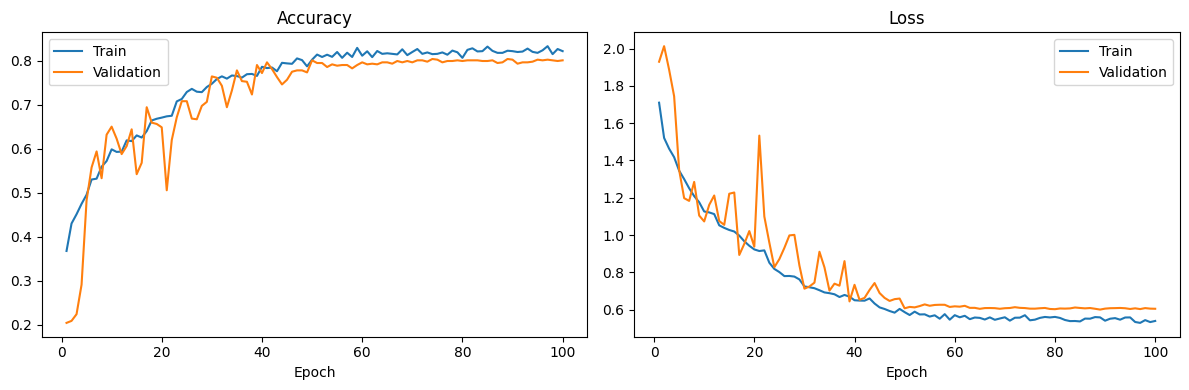

Epoch tốt nhất: 89/100 | train – val accuracy = 0.019


In [37]:
h = history.history
ep = range(1, len(h['loss']) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ep, h['accuracy'], label='Train'); plt.plot(ep, h['val_accuracy'], label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(ep, h['loss'], label='Train'); plt.plot(ep, h['val_loss'], label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/training_curves.png', dpi=150)
plt.show()

best_epoch = int(np.argmin(h['val_loss'])) + 1      # khớp với epoch mà checkpoint đã lưu
gap = h['accuracy'][best_epoch - 1] - h['val_accuracy'][best_epoch - 1]
print(f'Epoch tốt nhất: {best_epoch}/{len(h["loss"])} | train – val accuracy = {gap:.3f}')
if gap > 0.15:
    print('⚠ Overfitting: tăng Dropout lên 0.3–0.4 hoặc tăng mức tăng cường dữ liệu')

Cell 9 – Đánh giá: tập test 6 lớp, riêng 5 loài hoa, riêng lớp Khác

Test accuracy (6 lớp: TF test + Khác) = 0.8250
              precision    recall  f1-score   support

       daisy      0.871     0.862     0.866        94
   dandelion      0.860     0.828     0.844       134
       roses      0.782     0.708     0.743        96
  sunflowers      0.864     0.913     0.888       104
      tulips      0.780     0.832     0.805       119
       other      0.793     0.800     0.796       110

    accuracy                          0.825       657
   macro avg      0.825     0.824     0.824       657
weighted avg      0.825     0.825     0.824       657

5 loài hoa (TF test): accuracy 83.0% | bị đoán nhầm thành Khác 4.2%
Hoa ngoài 5 loài : nhận ra là Khác 73.8% (61 ảnh)
Không phải hoa   : nhận ra là Khác 87.8% (49 ảnh)
Ảnh Khác bị web chặn (Khác hoặc chưa chắc chắn): 88.2%


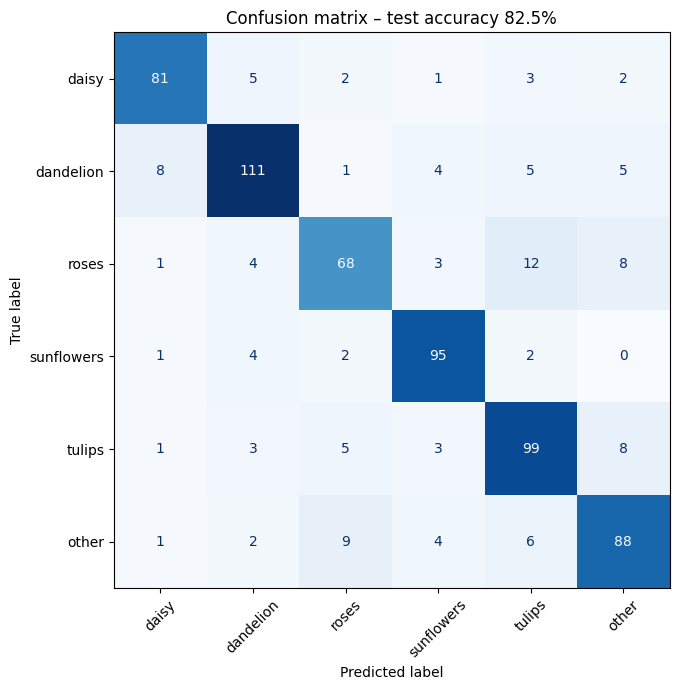

In [34]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f'Test accuracy (6 lớp: TF test + Khác) = {test_acc:.4f}')

probs  = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
OTHER  = class_names.index('other')   # = 5

print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)

# 5 loài hoa trên đúng tập TF test: so được với v1 (80,4%)
is_flower = y_true != OTHER
flower_acc = np.mean(y_pred[is_flower] == y_true[is_flower])
print(f'5 loài hoa (TF test): accuracy {flower_acc:.1%} | bị đoán nhầm thành Khác {np.mean(y_pred[is_flower] == OTHER):.1%}')

# Lớp Khác, tách 2 nửa theo tên file (Cell 4)
file_names = np.array([os.path.basename(p) for p in test_files])
for prefix, label in [('hoakhac_', 'Hoa ngoài 5 loài'), ('khonghoa_', 'Không phải hoa')]:
    m = np.char.startswith(file_names, prefix)
    print(f'{label:17}: nhận ra là Khác {np.mean(y_pred[m] == OTHER):.1%} ({m.sum()} ảnh)')

# Quy tắc trên web: đứng đầu là Khác -> "không phải hoa"; độ tin cậy dưới ngưỡng -> "chưa chắc chắn"
blocked = (y_pred == OTHER) | (probs.max(axis=1) < THRESHOLD)
print(f'Ảnh Khác bị web chặn (Khác hoặc chưa chắc chắn): {np.mean(blocked[~is_flower]):.1%}')

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Confusion matrix – test accuracy {test_acc:.1%}')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/confusion_matrix.png', dpi=150)
plt.show()

Cell 10 – Xuất file cho web và kiểm tra nạp lại

In [35]:
model.save(f'{MODEL_DIR}/flower_cnn.keras')

model_info = {
    'version': VERSION,
    'uncertain_threshold': THRESHOLD,
    'charts': {'training_curves': '/static/model/training_curves.png',
               'confusion_matrix': '/static/model/confusion_matrix.png'},
    'img_size': list(IMG_SIZE),
    'class_names': class_names,
    'architecture': ['Input 180×180×3', 'Rescaling 1/255', 'Augment: Flip · Rotation · Zoom',
                     'Augment màu: Hue · Saturation · Grayscale', 'Conv 16 + L2 + BN + Pool', 'Conv 32 + L2 + BN + Pool',
                     'Conv 64 + L2 + BN + Pool', 'Conv 128 + L2 + BN + Pool', 'GlobalAveragePooling', 'Dropout 0.2', 'Softmax 6'],
    'num_images': counts,
    'test_accuracy': round(float(test_acc), 4),
    'flower_test_accuracy': round(float(flower_acc), 4),     # riêng 5 loài trên TF test, để so với v1
    'per_class': {c: {'precision': round(report[c]['precision'], 4),
                      'recall':    round(report[c]['recall'], 4),
                      'f1':        round(report[c]['f1-score'], 4)} for c in class_names},
    'confusion_matrix': confusion_matrix(y_true, y_pred).tolist(),       # hàng = thực tế, cột = dự đoán
    'history': {k: [round(float(v), 4) for v in h[k]] for k in ['accuracy', 'val_accuracy', 'loss', 'val_loss']},
    'epochs_trained': len(h['loss']),
    'best_epoch': best_epoch,
    'trained_at': datetime.date.today().isoformat(),
    'tensorflow_version': tf.__version__,
}
with open(f'{MODEL_DIR}/model_info.json', 'w', encoding='utf-8') as f:
    json.dump(model_info, f, ensure_ascii=False, indent=2)

# Kiểm tra file .keras nạp lại được và cho kết quả giống hệt
loaded = keras.models.load_model(f'{MODEL_DIR}/flower_cnn.keras')
print('Chênh lệch sau khi nạp lại:', np.abs(loaded.predict(test_ds, verbose=0) - probs).max())

for f in sorted(os.listdir(MODEL_DIR)):
    print(f'{f:22} {os.path.getsize(f"{MODEL_DIR}/{f}") / 1e6:.1f} MB')

Chênh lệch sau khi nạp lại: 0.0
class_names.json       0.0 MB
confusion_matrix.png   0.1 MB
flower_cnn.keras       1.3 MB
model_info.json        0.0 MB
training_curves.png    0.1 MB


Cell 11 – Thử phân loại 1 ảnh ngoài bộ dữ liệu (thử cả ảnh không phải hoa)

Saving download (30).jpg to download (30) (1).jpg
Kết quả: other (92.6%)
Top 3  : other 92.6%, roses 6.3%, tulips 0.8%
→ Web sẽ báo: không phải 1 trong 5 loài hoa Anthea nhận diện


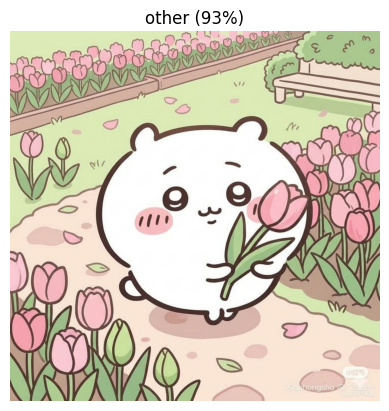

In [36]:
from google.colab import files

model_test = keras.models.load_model(f'{MODEL_DIR}/flower_cnn.keras')
with open(f'{MODEL_DIR}/class_names.json') as f:
    names = json.load(f)

fname, data = next(iter(files.upload().items()))   # chọn 1 ảnh JPG/PNG

img = tf.io.decode_image(data, channels=3, expand_animations=False)
p = model_test.predict(tf.image.resize(img, IMG_SIZE)[tf.newaxis], verbose=0)[0]
top3 = p.argsort()[::-1][:3]

print(f'Kết quả: {names[top3[0]]} ({p[top3[0]]:.1%})')
print('Top 3  :', ', '.join(f'{names[i]} {p[i]:.1%}' for i in top3))
if names[top3[0]] == 'other':
    print('→ Web sẽ báo: không phải 1 trong 5 loài hoa Anthea nhận diện')
elif p[top3[0]] < THRESHOLD:
    print('→ Web sẽ báo: chưa chắc chắn')

plt.imshow(img.numpy())
plt.title(f'{names[top3[0]]} ({p[top3[0]]:.0%})')
plt.axis('off')
plt.show()